# Import lib etc

In [41]:
pip install "kagglehub[pandas-datasets]"

Note: you may need to restart the kernel to use updated packages.


Import dataframe & pick only 3 games

In [42]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, "kieranpoc/steam-reviews", "weighted_score_above_08.csv")

/opt/anaconda3/lib/python3.12/site-packages/kagglehub/pandas_datasets.py:92: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  result = read_function(


In [43]:
games = [
    "Counter-Strike 2",
    "PUBG: BATTLEGROUNDS",
    "Grand Theft Auto V"
]

df_3games = df[df["game"].isin(games)].copy()

print(df_3games.shape)
df_3games["game"].value_counts()

(7365, 24)


game
Counter-Strike 2       3017
PUBG: BATTLEGROUNDS    2404
Grand Theft Auto V     1944
Name: count, dtype: int64

# 1. Prepare Gemini Labeling Prompt


In [44]:
with open("../prompts/codebook_exact.txt", "r") as f:
    SYSTEM = f.read()

GEMINI_MODEL = "gemini-3.5-flash-lite"
TEMPERATURE = 0

SCHEMA = {
    "type": "object",
    "properties": {
        "harm_mention": {"type": "string", "enum": ["yes", "no", "uncertain"]},
        "harm_reason": {"type": "string"},
        "irony": {"type": "string", "enum": ["yes", "no", "uncertain"]},
        "irony_reason": {"type": "string"},
        "gender_age": {"type": "string", "enum": ["none", "gender", "age", "both", "uncertain"]},
        "gender_age_reason": {"type": "string"}
    },
    "required": [
        "harm_mention", "harm_reason",
        "irony", "irony_reason",
        "gender_age", "gender_age_reason"
    ]
}


# 2. Set Up Gemini API and Labeling Function


In [45]:
pip install google-genai python-dotenv


Note: you may need to restart the kernel to use updated packages.


In [46]:
import os
import json
import time
import pandas as pd
from dotenv import load_dotenv
from google import genai
from google.genai import types, errors
import random

load_dotenv("../.env")
# Set USE_VERTEX=1 in .env to go through Google Cloud (Vertex AI) instead of an AI Studio API key.
# Needs: `gcloud auth application-default login` + Vertex AI API enabled on the project.
if os.environ.get("USE_VERTEX") == "1":
    client = genai.Client(
        vertexai=True,
        project=os.environ["GOOGLE_CLOUD_PROJECT"],
        location=os.environ.get("GOOGLE_CLOUD_LOCATION", "global"),
    )
else:
    client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

def make_payload(row):
    if "recommendation" in row.index:
        recommendation = row["recommendation"]
    elif "voted_up" in row.index:
        recommendation = row["voted_up"]
    else:
        raise KeyError("No recommendation column found")

    if isinstance(recommendation, bool):
        recommendation = "Recommended" if recommendation else "Not recommended"

    return {
        "game": row["game"],
        "review": row["review"],
        "recommendation": recommendation
    }

RETRY_CODES = {429, 500, 503, 504}

def label_review(row, max_retries=8):
    for attempt in range(max_retries):
        try:
            response = client.models.generate_content(
                model=GEMINI_MODEL,
                contents=json.dumps(make_payload(row), ensure_ascii=False),
                config=types.GenerateContentConfig(
                    system_instruction=SYSTEM,
                    temperature=TEMPERATURE,
                    response_mime_type="application/json",
                    response_schema=SCHEMA
                )
            )
            return json.loads(response.text)

        except errors.APIError as e:
            # only retry capacity/rate-limit errors; exponential backoff + jitter
            if e.code not in RETRY_CODES or attempt == max_retries - 1:
                raise
            wait = min(10 * 2 ** attempt, 300) + random.uniform(0, 5)
            print(f"Attempt {attempt + 1} failed ({e.code}); retrying in {wait:.0f}s")
            time.sleep(wait)


# 3. Trial Batch on Human Positive Cases

Test Gemini on 10 reviews where Annotator 1 labeled toxicity or irony as `yes`, then compare the human and Gemini labels.


In [47]:
annotator_1 = pd.read_csv("../data/blind_labelling_annotator_1.csv")

positive_cases = annotator_1[
    (annotator_1["toxicity_clean"] == "yes") |
    (annotator_1["irony_clean"] == "yes")
].copy()

trial_10 = positive_cases.sample(n=10, random_state=211).copy()

trial_10[["case_id", "game", "review", "recommendation", "toxicity_clean", "irony_clean"]]


,case_id,game,review,recommendation,toxicity_clean,irony_clean
9,Re1f7a89d0f,Counter-Strike 2,Gaben mother died useless team steam support f...,Not recommended,yes,no
43,R2d97970a5a,Counter-Strike 2,get ready to be cursed by angry iranians and b...,Recommended,yes,yes
7,Re552c45375,Grand Theft Auto V,ligma balls,Recommended,yes,no
33,Rc3d567aeff,PUBG: BATTLEGROUNDS,IT'S LIKE BEING KICKED IN THE GENITALS BUT YOU...,Recommended,yes,no
21,R56a79a750a,Grand Theft Auto V,"Take Two, you can go shove your modding polici...",Not recommended,yes,no
48,R7c5ffd9f01,Counter-Strike 2,very good game i regret my life fro playing it...,Recommended,yes,yes
35,R92f475cda2,Counter-Strike 2,Didn't clutch. Got kicked. Uninstalled Steam...,Recommended,no,yes
57,R5381f82d32,Grand Theft Auto V,This game is highly unpolished and has constan...,Not recommended,yes,no
62,Rdfeb67c50a,Counter-Strike 2,"horrible game, very bad, most garbage ive play...",Recommended,no,yes
80,R94bff5e71c,Counter-Strike 2,"after so long, they decided to make this game ...",Not recommended,yes,yes


In [48]:
from IPython.display import clear_output

MODEL_TAG = GEMINI_MODEL.replace("/", "_")
CACHE = f"../data/gemini_trial_10_{MODEL_TAG}.jsonl"   # results are kept per model
PAUSE = 0.5   # seconds between requests (was 4.2)

done = {}
if os.path.exists(CACHE):
    with open(CACHE) as f:
        done = {json.loads(l)["case_id"]: json.loads(l) for l in f}

total = len(trial_10)
recent = []
n_new = 0
t0 = time.time()

def snip(text, n=110):
    text = str(text).replace("\n", " ")
    return text if len(text) <= n else text[:n] + "..."

def show(current=None):
    n_done = len(done)
    pct = n_done / total
    filled = int(pct * 30)
    bar = "█" * filled + "░" * (30 - filled)
    elapsed = time.time() - t0
    eta = (elapsed / n_new) * (total - n_done) if n_new else 0
    clear_output(wait=True)
    print(f"Model: {GEMINI_MODEL}")
    print(f"[{bar}] {pct*100:5.1f}%  ({n_done}/{total})  elapsed {elapsed:.0f}s  ETA ~{eta:.0f}s\n")
    for it in recent[-2:]:
        tox = "SAME" if it["human_tox"] == it["gem_tox"] else "DIFF"
        iro = "SAME" if it["human_iro"] == it["gem_iro"] else "DIFF"
        print(f"✔ SOLVED  {it['case_id']} | {it['game']}")
        print(f"   \"{snip(it['review'])}\"")
        print(f"   Gemini: toxicity={it['gem_tox']}  irony={it['gem_iro']}")
        print(f"   Human : toxicity={it['human_tox']}  irony={it['human_iro']}   -> tox {tox}, irony {iro}\n")
    if current is not None:
        print(f"⏳ PROCESSING  {current['case_id']} | {current['game']}")
        print(f"   \"{snip(current['review'])}\"\n")

show()
for _, row in trial_10.iterrows():
    cid = row["case_id"]
    if cid in done:
        continue
    show(current=row)
    result = label_review(row)
    entry = {"case_id": cid, "model": GEMINI_MODEL, **result}
    with open(CACHE, "a") as f:
        f.write(json.dumps(entry) + "\n")
    done[cid] = entry
    n_new += 1
    recent.append({
        "case_id": cid, "game": row["game"], "review": row["review"],
        "gem_tox": result["harm_mention"], "gem_iro": result["irony"],
        "human_tox": row["toxicity_clean"], "human_iro": row["irony_clean"],
    })
    show()
    time.sleep(PAUSE)

print(f"DONE: {len(done)}/{total} in {time.time() - t0:.0f}s")

rows = []
for _, row in trial_10.iterrows():
    result = done[row["case_id"]]
    rows.append({
        "case_id": row["case_id"],
        "model": GEMINI_MODEL,
        "game": row["game"],
        "review": row["review"],
        "recommendation": row["recommendation"],
        "human_toxicity": row["toxicity_clean"],
        "gemini_toxicity": result["harm_mention"],
        "human_irony": row["irony_clean"],
        "gemini_irony": result["irony"],
        "harm_reason": result["harm_reason"],
        "irony_reason": result["irony_reason"],
    })

trial_results = pd.DataFrame(rows)
trial_results["toxicity_match"] = trial_results["human_toxicity"] == trial_results["gemini_toxicity"]
trial_results["irony_match"] = trial_results["human_irony"] == trial_results["gemini_irony"]
trial_results.to_csv(f"../data/gemini_trial_10_{MODEL_TAG}.csv", index=False)
trial_results

Model: gemini-3.5-flash-lite
[██████████████████████████████] 100.0%  (10/10)  elapsed 0s  ETA ~0s

DONE: 10/10 in 0s


,case_id,model,game,review,recommendation,human_toxicity,gemini_toxicity,human_irony,gemini_irony,harm_reason,irony_reason,toxicity_match,irony_match
0,Re1f7a89d0f,gemini-3.5-flash-lite,Counter-Strike 2,Gaben mother died useless team steam support f...,Not recommended,yes,yes,no,no,The review contains severe targeted insults an...,The text expresses extreme anger and hostility...,True,True
1,R2d97970a5a,gemini-3.5-flash-lite,Counter-Strike 2,get ready to be cursed by angry iranians and b...,Recommended,yes,yes,yes,yes,"The review explicitly mentions hackers, which ...",The reviewer recommends a game they describe a...,True,True
2,Re552c45375,gemini-3.5-flash-lite,Grand Theft Auto V,ligma balls,Recommended,yes,yes,no,no,The review uses a direct vulgar meme phrase fu...,There is no identifiable ironic mechanism pres...,True,True
3,Rc3d567aeff,gemini-3.5-flash-lite,PUBG: BATTLEGROUNDS,IT'S LIKE BEING KICKED IN THE GENITALS BUT YOU...,Recommended,yes,no,no,no,The text uses a painful physical analogy to ex...,The review expresses genuine mixed feelings of...,False,True
4,R56a79a750a,gemini-3.5-flash-lite,Grand Theft Auto V,"Take Two, you can go shove your modding polici...",Not recommended,yes,yes,no,no,"The review contains a hostile, vulgar insult d...",The criticism and hostility are expressed lite...,True,True
5,R7c5ffd9f01,gemini-3.5-flash-lite,Counter-Strike 2,very good game i regret my life fro playing it...,Recommended,yes,yes,yes,yes,The reviewer explicitly mentions acquiring tox...,The reviewer states they regret playing and do...,True,True
6,R92f475cda2,gemini-3.5-flash-lite,Counter-Strike 2,Didn't clutch. Got kicked. Uninstalled Steam...,Recommended,no,no,yes,yes,Getting kicked and raging from failing to clut...,The review uses humor and playful exaggeration...,True,True
7,R5381f82d32,gemini-3.5-flash-lite,Grand Theft Auto V,This game is highly unpolished and has constan...,Not recommended,yes,yes,no,no,The review explicitly complains about hackers ...,The review expresses straightforward dissatisf...,True,True
8,Rdfeb67c50a,gemini-3.5-flash-lite,Counter-Strike 2,"horrible game, very bad, most garbage ive play...",Recommended,no,no,yes,yes,The review expresses intense dissatisfaction a...,There is a clear polarity-contrast verbal iron...,True,True
9,R94bff5e71c,gemini-3.5-flash-lite,Counter-Strike 2,"after so long, they decided to make this game ...",Not recommended,yes,yes,yes,yes,The review explicitly complains about hackers ...,The reviewer uses ironic wordplay on the game'...,True,True


In [49]:
print("Toxicity matches:", trial_results["toxicity_match"].sum(), "/", len(trial_results))
print("Irony matches:", trial_results["irony_match"].sum(), "/", len(trial_results))


Toxicity matches: 9 / 10
Irony matches: 10 / 10


# 4. Scale-up: label every review

Run the setup cells above first (they define `df_3games`, the prompt, the client and `make_payload`), then the three cells below. The plumbing (cache lookup, parallel requests, retries, progress panel, export) lives in `../scripts/steam_labeling.py`.

- **Resumable:** every finished review is appended to `../data/gemini_full_<model>.jsonl`. Re-running skips anything already stored, so nothing is paid for twice.
- **Failures don't stop the run:** a review that still fails after the retries is shown in the panel; run the middle cell again to retry only those.
- **Try small first:** set `limit=200` in the first cell, then back to `None` for the full run.
- Interrupt the kernel to pause; run the middle cell again to continue.

In [50]:
import sys, importlib
sys.path.insert(0, "../scripts")
import steam_labeling
importlib.reload(steam_labeling)   # picks up edits to scripts/steam_labeling.py without restarting the kernel

run = steam_labeling.LabelRun(
    df=df_3games, client=client, model=GEMINI_MODEL,
    system=SYSTEM, schema=SCHEMA, temperature=TEMPERATURE, make_payload=make_payload,
    batch_size=100,   # display only; every review is saved the moment it finishes
    workers=8,        # parallel requests
    limit=None,       # e.g. 200 for a quick dry run; None = all reviews
)

Vertex AI · gemini-3.5-flash-lite
7,365 reviews in scope · 197 already labeled in ../data/gemini_full_gemini-3.5-flash-lite.jsonl (skipped) · 7,168 to go


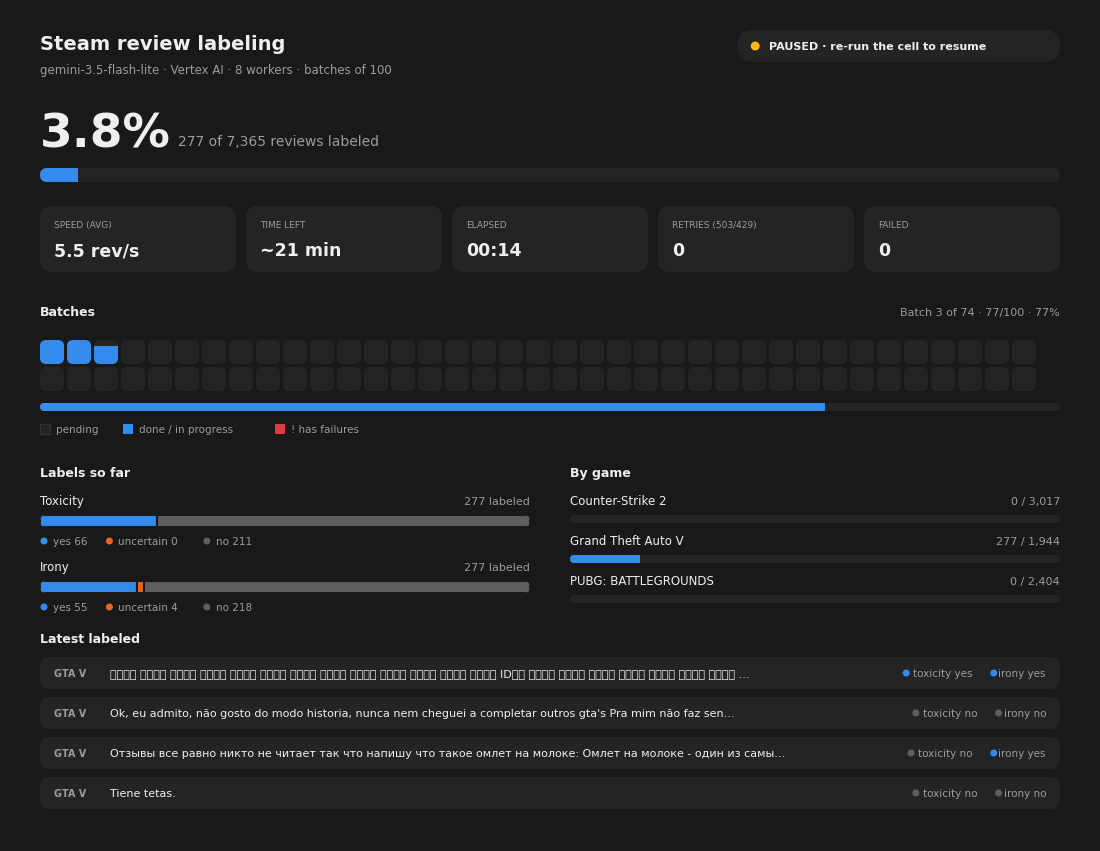

PAUSED: 277/7,365 labeled · 0 failed · this run took 00:14
Re-run this cell to continue where it stopped (finished reviews are skipped).


In [51]:
run.start()

In [ ]:
out = run.export()